# COMP813 — Cross-Dataset Generalisation of NLP Models for Phishing Email Detection

## Model 3: Bidirectional LSTM (BiLSTM)

### Objective

This notebook implements a Bidirectional Long Short-Term Memory
(BiLSTM) neural network for phishing/spam email detection.

Unlike the TF-IDF-based Logistic Regression and Linear SVM models,
the BiLSTM processes the sequence of words in each email and can
capture contextual relationships between words.

### Experimental Design

- Training data: Enron training split
- Validation data: Enron validation split
- Test data: Enron test split
- External evaluation: CEAS-08 (performed separately)

### Input

Email subject + email body

### Target

- 0 = Legitimate
- 1 = Phishing/Spam

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

### Important Methodological Constraint

The tokenizer and vocabulary are fitted exclusively on the Enron
training data. Validation and test data are transformed using the
fitted tokenizer without updating the vocabulary.

CEAS-08 is not used during model development.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import json
import re

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


## 1. Load Dataset

The same fixed Enron training, validation, and test splits used
for the Logistic Regression and Linear SVM models are used here.

Using identical splits allows the BiLSTM results to be compared
directly with the traditional machine-learning models.

In [9]:
train_df = pd.read_csv("enron_train.csv")
val_df = pd.read_csv("enron_val.csv")
test_df = pd.read_csv("enron_test.csv")

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

Training set: (20596, 2)
Validation set: (4414, 2)
Test set: (4414, 2)


## 2. Dataset Overview

In [10]:
print("Training set label distribution:")
print(train_df["label"].value_counts())
print()

print("Validation set label distribution:")
print(val_df["label"].value_counts())
print()

print("Test set label distribution:")
print(test_df["label"].value_counts())

Training set label distribution:
label
0    10831
1     9765
Name: count, dtype: int64

Validation set label distribution:
label
0    2321
1    2093
Name: count, dtype: int64

Test set label distribution:
label
0    2322
1    2092
Name: count, dtype: int64


In [11]:
train_df.head()

,text,label
0,subject: fw : cancel pedricktown visit body: a...,0
1,subject: fortune body: here ' s the fortune li...,0
2,subject: re : org charts body: i have received...,0
3,subject: stoop it deaaaaad in it ' s tracks bo...,1
4,subject: greatly improve your stamina body: my...,1


## 3. Prepare Features and Target

Only the combined subject and body text is used as input.

The sender, receiver, date, and URL metadata are excluded so that
the experiment remains focused on text-based phishing detection.

In [12]:
X_train = train_df["text"].astype(str)
y_train = train_df["label"].values

X_val = val_df["text"].astype(str)
y_val = val_df["label"].values

X_test = test_df["text"].astype(str)
y_test = test_df["label"].values

## 4. Tokenization

A vocabulary is constructed exclusively from the Enron training
data.

Words occurring fewer than two times are excluded from the vocabulary.
An `<UNK>` token represents words that are not present in the
training vocabulary.

Validation and test sets are encoded using the fixed training
vocabulary without updating it.

In [13]:
from collections import Counter

MAX_VOCAB_SIZE = 50000
MAX_SEQUENCE_LENGTH = 500
MIN_WORD_FREQUENCY = 2

# --------------------------------------------------
# Basic tokenizer
# --------------------------------------------------

def tokenize_text(text):
    return re.findall(r"\b\w+\b", text.lower())


# --------------------------------------------------
# Build vocabulary ONLY from training data
# --------------------------------------------------

word_counts = Counter()

for text in X_train:
    word_counts.update(tokenize_text(text))

print("Unique words before filtering:", len(word_counts))


# --------------------------------------------------
# Select most frequent words
# --------------------------------------------------

most_common_words = [
    word
    for word, count in word_counts.most_common()
    if count >= MIN_WORD_FREQUENCY
][:MAX_VOCAB_SIZE - 2]


# --------------------------------------------------
# Special tokens
# --------------------------------------------------

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_to_index = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for idx, word in enumerate(most_common_words, start=2):
    word_to_index[word] = idx

index_to_word = {
    idx: word
    for word, idx in word_to_index.items()
}

print("Vocabulary size:", len(word_to_index))

Unique words before filtering: 131063
Vocabulary size: 50000


## 5. Sequence Preparation

Each email is converted into a sequence of integer token IDs using
the vocabulary created from the training data.

Sequences longer than 500 tokens are truncated, while shorter
sequences are padded with the `<PAD>` token.

The same vocabulary and sequence length are applied to the
training, validation, and test sets.

In [14]:
def text_to_sequence(text, word_to_index, max_length):

    tokens = tokenize_text(text)

    sequence = [
        word_to_index.get(token, word_to_index[UNK_TOKEN])
        for token in tokens
    ]

    # Truncate
    sequence = sequence[:max_length]

    # Pad
    if len(sequence) < max_length:
        sequence += [
            word_to_index[PAD_TOKEN]
        ] * (max_length - len(sequence))

    return sequence


X_train_seq = np.array([
    text_to_sequence(text, word_to_index, MAX_SEQUENCE_LENGTH)
    for text in X_train
])

X_val_seq = np.array([
    text_to_sequence(text, word_to_index, MAX_SEQUENCE_LENGTH)
    for text in X_val
])

X_test_seq = np.array([
    text_to_sequence(text, word_to_index, MAX_SEQUENCE_LENGTH)
    for text in X_test
])


print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Test sequences:", X_test_seq.shape)

Training sequences: (20596, 500)
Validation sequences: (4414, 500)
Test sequences: (4414, 500)


## 6. PyTorch Dataset Preparation

The tokenized sequences and corresponding labels are converted into
PyTorch datasets and data loaders for model training and evaluation.

In [15]:
class EmailDataset(Dataset):

    def __init__(self, sequences, labels):
        self.sequences = torch.tensor(
            sequences,
            dtype=torch.long
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]


train_dataset = EmailDataset(X_train_seq, y_train)
val_dataset = EmailDataset(X_val_seq, y_val)
test_dataset = EmailDataset(X_test_seq, y_test)


BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 322
Validation batches: 69
Test batches: 69


## 7. BiLSTM Architecture

A Bidirectional LSTM is used to capture contextual information from
both directions of the email text.

The architecture consists of:

1. Embedding layer
2. Bidirectional LSTM layer
3. Dropout layer
4. Fully connected output layer

The model produces a single logit for binary classification.

In [16]:
class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        dropout=0.3
    ):
        super(BiLSTMClassifier, self).__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):

        embedded = self.embedding(x)

        _, (hidden, _) = self.lstm(embedded)

        # Forward and backward final hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        output = self.dropout(combined_hidden)

        output = self.fc(output)

        return output.squeeze(1)

In [17]:
VOCAB_SIZE = len(word_to_index)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    dropout=0.3
)

model = model.to(device)

print(model)

BiLSTMClassifier(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)


## 8. Training Configuration

Binary Cross-Entropy with Logits is used as the loss function.

A positive-class weight is calculated from the training-set class
distribution so that the slightly less frequent phishing/spam class
is not underweighted during training.

The Adam optimizer is used for parameter optimization.

In [18]:
# Calculate positive class weight
negative_count = np.sum(y_train == 0)
positive_count = np.sum(y_train == 1)

pos_weight_value = negative_count / positive_count

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32
).to(device)

print(f"Positive class weight: {pos_weight_value:.4f}")


# Loss function
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)


# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

Positive class weight: 1.1092


## 9. Training Functions

Separate training and validation functions are used to keep the
training process reproducible and allow validation performance to
be monitored after each epoch.

In [19]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for sequences, labels in dataloader:

        sequences = sequences.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(sequences)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return avg_loss, accuracy, f1

In [20]:
def evaluate_model(model, dataloader, criterion, device):

    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for sequences, labels in dataloader:

            sequences = sequences.to(device)
            labels = labels.to(device)

            outputs = model(sequences)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= 0.5).float()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        precision,
        recall,
        f1
    )

## 10. Model Training

The BiLSTM is trained for a maximum of eight epochs.

Validation F1-score is monitored after each epoch. Early stopping
is used to prevent unnecessary training once validation performance
stops improving.

The model state with the best validation F1-score is retained.

In [21]:
EPOCHS = 8
PATIENCE = 2

best_val_f1 = 0.0
patience_counter = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

best_model_state = None

start_time = time.time()

for epoch in range(EPOCHS):

    train_loss, train_accuracy, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_precision,
        val_recall,
        val_f1
    ) = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["train_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Early stopping
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        patience_counter = 0

        best_model_state = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

training_time = time.time() - start_time

print(f"\nTotal training time: {training_time / 60:.2f} minutes")
print(f"Best validation F1: {best_val_f1:.4f}")

Epoch 1/8 | Train Loss: 0.2551 | Train F1: 0.8913 | Val Loss: 0.1377 | Val F1: 0.9520
Epoch 2/8 | Train Loss: 0.0869 | Train F1: 0.9707 | Val Loss: 0.2185 | Val F1: 0.9139
Epoch 3/8 | Train Loss: 0.0661 | Train F1: 0.9773 | Val Loss: 0.0896 | Val F1: 0.9717
Epoch 4/8 | Train Loss: 0.0251 | Train F1: 0.9921 | Val Loss: 0.0711 | Val F1: 0.9792
Epoch 5/8 | Train Loss: 0.0380 | Train F1: 0.9870 | Val Loss: 0.1009 | Val F1: 0.9746
Epoch 6/8 | Train Loss: 0.0629 | Train F1: 0.9793 | Val Loss: 0.1107 | Val F1: 0.9638
Early stopping triggered.

Total training time: 0.95 minutes
Best validation F1: 0.9792


## 11. Restore Best Validation Model

The model state corresponding to the highest validation F1-score
is restored before evaluation on the held-out Enron test set.

This prevents the final test evaluation from using a later model
state that performed worse on the validation data.

In [22]:
# Restore the model with the best validation F1
model.load_state_dict(best_model_state)

# Move the model back to the selected device
model = model.to(device)

print(f"Best validation F1 restored: {best_val_f1:.4f}")

Best validation F1 restored: 0.9792


## 12. Training Curves

Training and validation loss and F1-score are plotted across
epochs to examine the learning behaviour of the BiLSTM and
identify potential overfitting.

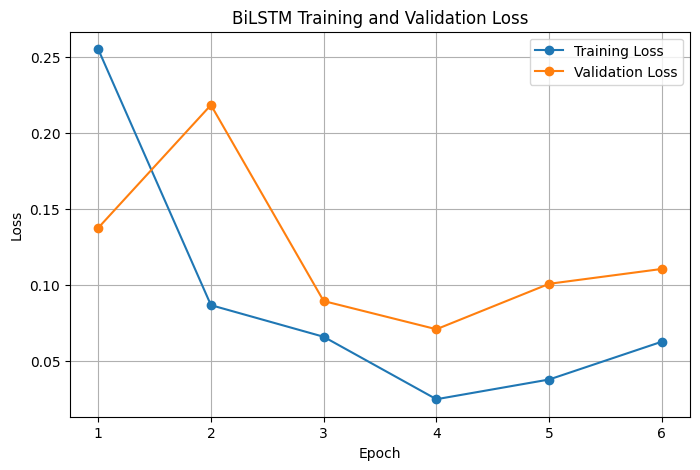

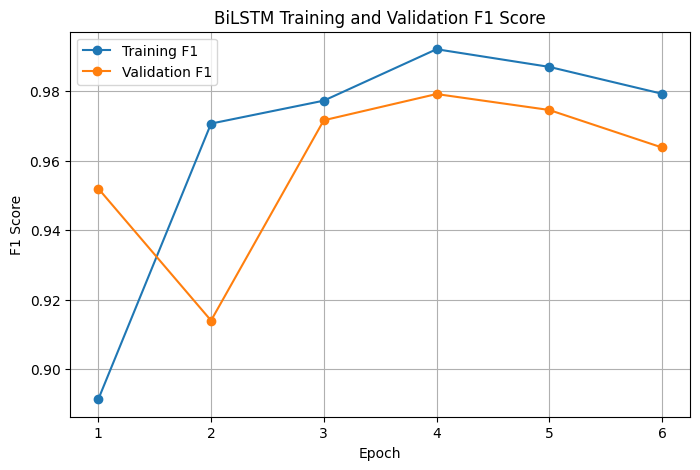

In [23]:
epochs_completed = range(1, len(history["train_loss"]) + 1)

# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BiLSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# F1 curve
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    history["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    epochs_completed,
    history["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("BiLSTM Training and Validation F1 Score")
plt.legend()
plt.grid(True)
plt.show()

## 13. Final Enron Test Evaluation

The best-performing model checkpoint, selected using validation F1,
is evaluated on the held-out Enron test set.

The test set was not used during model selection or training.

In [24]:
# Evaluate the restored best model on the test set

(
    test_loss,
    test_accuracy,
    test_precision,
    test_recall,
    test_f1
) = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

print("BiLSTM — ENRON TEST")
print("=" * 50)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")

BiLSTM — ENRON TEST
Accuracy : 0.9783
Precision: 0.9748
Recall   : 0.9794
F1 Score : 0.9771


In [25]:
# Generate detailed predictions for the test set

model.eval()

all_test_predictions = []
all_test_labels = []

with torch.no_grad():

    for sequences, labels in test_loader:

        sequences = sequences.to(device)

        outputs = model(sequences)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_labels.extend(
            labels.numpy()
        )


print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

               precision    recall  f1-score   support

   Legitimate       0.98      0.98      0.98      2322
Phishing/Spam       0.97      0.98      0.98      2092

     accuracy                           0.98      4414
    macro avg       0.98      0.98      0.98      4414
 weighted avg       0.98      0.98      0.98      4414



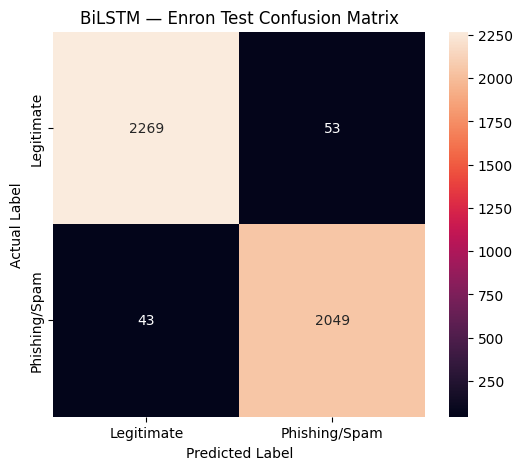

In [26]:
cm_test = confusion_matrix(
    all_test_labels,
    all_test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    xticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing/Spam"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("BiLSTM — Enron Test Confusion Matrix")

plt.show()

## 14. Results Summary

In [27]:
bilstm_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Validation": [
        history["val_accuracy"][np.argmax(history["val_f1"])],
        history["val_precision"][np.argmax(history["val_f1"])],
        history["val_recall"][np.argmax(history["val_f1"])],
        best_val_f1
    ],
    "Test": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

bilstm_results

,Metric,Validation,Test
0,Accuracy,0.980290,0.978251
1,Precision,0.978988,0.974786
2,Recall,0.979455,0.979446
3,F1 Score,0.979221,0.977110


## 15. Observations

The BiLSTM achieved an F1-score of 97.71% on the held-out Enron
test set.

The best validation F1-score of 97.92% was achieved at Epoch 4.
After this point, validation F1 declined while validation loss
increased, resulting in early stopping.

The final test results show that the BiLSTM correctly identified
2,049 of the 2,092 phishing/spam emails and 2,269 of the 2,322
legitimate emails.

The BiLSTM provides a neural sequence-based comparison to the
TF-IDF-based Logistic Regression and Linear SVM models.

The three models will be compared further using an unseen external
dataset. In particular, the cross-dataset experiment will determine
whether the strong in-domain performance observed on Enron is
maintained when the models are applied to CEAS-08.

In [28]:
import os
import json
import torch

os.makedirs("/content/models", exist_ok=True)

# --------------------------------------------------
# Save model checkpoint
# --------------------------------------------------

checkpoint = {
    "model_state_dict": model.state_dict(),
    "vocab_size": len(word_to_index),
    "embedding_dim": 128,
    "hidden_dim": 128,
    "dropout": 0.3,
    "max_sequence_length": MAX_SEQUENCE_LENGTH
}

torch.save(
    checkpoint,
    "/content/models/bilstm_enron.pt"
)


# --------------------------------------------------
# Save vocabulary
# --------------------------------------------------

with open(
    "/content/models/bilstm_vocabulary.json",
    "w"
) as f:

    json.dump(
        word_to_index,
        f
    )


# --------------------------------------------------
# Save training history
# --------------------------------------------------

with open(
    "/content/models/bilstm_training_history.json",
    "w"
) as f:

    json.dump(
        history,
        f
    )


print("BiLSTM model, vocabulary, and training history saved successfully.")

BiLSTM model, vocabulary, and training history saved successfully.
